Yuliia Chernysheva  
November 11, 2026  
CSC 2267: Multiple Regression Assignment

**Dataset Summary**
  
This dataset contains information about automobile miles per gallon (`MPG`) based on the number of
cylinders, the displacement, the horsepower, the weight, the acceleration, the model year, the origin,
and the car.

Import libraries

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_regression

# Task 1: Read the data file from the Seaborn website

In [2]:
# Load the automobile MPG dataset directly from the Seaborn repository
data = sns.load_dataset('mpg')

# Task 2: Display the first five rows of data.

In [3]:
# Preview the first five records of the raw dataset
display(data.head())

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


# Task 3: Use the info() method to display the data types for the columns

In [4]:
# Inspect structural summary, column data types, and check for null values
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


# Task 4: Get the brand from the name column and store it in a new column named brand

In [5]:
# Extract the first word from the car name string as the brand
data["brand"] = data.apply(lambda x: x['name'].split()[0], axis=1)

# Verify the newly created "brand" column
data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,brand
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu,chevrolet
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320,buick
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite,plymouth
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst,amc
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino,ford


# Task 5: Drop the name column, and then display the first five rows of data.

In [6]:
# Drop the original 'name' column since brand is now isolated
cars_data = data.drop(columns=['name'])

# Display the first five rows of the updated DataFrame
display(cars_data.head())

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,brand
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford


# Task 6: Display all of the unique values in the brand column

In [7]:
# List all distinct brand names to inspect for typos and duplicates 
cars_data.brand.unique()

array(['chevrolet', 'buick', 'plymouth', 'amc', 'ford', 'pontiac',
       'dodge', 'toyota', 'datsun', 'volkswagen', 'peugeot', 'audi',
       'saab', 'bmw', 'chevy', 'hi', 'mercury', 'opel', 'fiat',
       'oldsmobile', 'chrysler', 'mazda', 'volvo', 'renault', 'toyouta',
       'maxda', 'honda', 'subaru', 'chevroelt', 'capri', 'vw',
       'mercedes-benz', 'cadillac', 'mercedes', 'vokswagen', 'triumph',
       'nissan'], dtype=object)

# Task 7: Review the brand data, and then fix the spelling errors in the brand column.

In [8]:
# Define dictionary mapping misspelled or alternate brand names to standard forms
corrections = {
    'chevy': 'chevrolet',
    'chevroelt': 'chevrolet',
    'toyouta': 'toyota',
    'maxda': 'mazda',
    'vw': 'volkswagen',
    'vokswagen': 'volkswagen',
    'mercedes-benz': 'mercedes'
}

# Standardize brand names across the dataset
cars_data["brand"] = cars_data["brand"].replace(corrections)

# List all distinct brand names 
cars_data.brand.unique()

array(['chevrolet', 'buick', 'plymouth', 'amc', 'ford', 'pontiac',
       'dodge', 'toyota', 'datsun', 'volkswagen', 'peugeot', 'audi',
       'saab', 'bmw', 'hi', 'mercury', 'opel', 'fiat', 'oldsmobile',
       'chrysler', 'mazda', 'volvo', 'renault', 'honda', 'subaru',
       'capri', 'mercedes', 'cadillac', 'triumph', 'nissan'], dtype=object)

# Task 8: Drop all rows from the DataFrame that have missing values

In [9]:
# Remove any records with missing values
cars_data = cars_data.dropna()

# Task 9: Get the two categorical columns (the one with the object data type), and store them in a list. Then, convert those columns to dummy variables, and store the results in a new DataFrame.

In [10]:
# Specify the two categorical columns
cat_columns = ['origin','brand']

# Generate dummy variables
dummies = pd.get_dummies(cars_data[cat_columns])

# Inspect the structure and column count of the dummy DataFrame
dummies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   origin_europe     392 non-null    bool 
 1   origin_japan      392 non-null    bool 
 2   origin_usa        392 non-null    bool 
 3   brand_amc         392 non-null    bool 
 4   brand_audi        392 non-null    bool 
 5   brand_bmw         392 non-null    bool 
 6   brand_buick       392 non-null    bool 
 7   brand_cadillac    392 non-null    bool 
 8   brand_capri       392 non-null    bool 
 9   brand_chevrolet   392 non-null    bool 
 10  brand_chrysler    392 non-null    bool 
 11  brand_datsun      392 non-null    bool 
 12  brand_dodge       392 non-null    bool 
 13  brand_fiat        392 non-null    bool 
 14  brand_ford        392 non-null    bool 
 15  brand_hi          392 non-null    bool 
 16  brand_honda       392 non-null    bool 
 17  brand_mazda       392 non-null    bool 


# Task 10: Drop categorical columns and join dummy variables into dataDummies

In [11]:
# Drop the original categorical columns from the dataset
dataDummies = cars_data.drop(columns=cat_columns)

# Join the generated dummy variables to the numeric DataFrame
dataDummies = dataDummies.join(dummies)

# Display the resulting columns and data types
dataDummies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 40 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mpg               392 non-null    float64
 1   cylinders         392 non-null    int64  
 2   displacement      392 non-null    float64
 3   horsepower        392 non-null    float64
 4   weight            392 non-null    int64  
 5   acceleration      392 non-null    float64
 6   model_year        392 non-null    int64  
 7   origin_europe     392 non-null    bool   
 8   origin_japan      392 non-null    bool   
 9   origin_usa        392 non-null    bool   
 10  brand_amc         392 non-null    bool   
 11  brand_audi        392 non-null    bool   
 12  brand_bmw         392 non-null    bool   
 13  brand_buick       392 non-null    bool   
 14  brand_cadillac    392 non-null    bool   
 15  brand_capri       392 non-null    bool   
 16  brand_chevrolet   392 non-null    bool   
 17  br

# Task 11: Rescale the data in the numeric columns, and then display the rescaled data

In [12]:
# Initialize StandardScaler to standardize numeric features
scaler = StandardScaler()

# List numeric predictor columns (excluding the target 'mpg' and dummy variables
num_cols = ['cylinders', 'displacement','horsepower','weight','acceleration','model_year']

# Fit scaler and transform numeric features in-place
dataDummies[num_cols] = scaler.fit_transform(dataDummies[num_cols])

# Display the standardized dataset
dataDummies.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_europe,origin_japan,origin_usa,...,brand_peugeot,brand_plymouth,brand_pontiac,brand_renault,brand_saab,brand_subaru,brand_toyota,brand_triumph,brand_volkswagen,brand_volvo
0,18.0,1.483947,1.077290,0.664133,0.620540,-1.285258,-1.625315,False,False,True,...,False,False,False,False,False,False,False,False,False,False
1,15.0,1.483947,1.488732,1.574594,0.843334,-1.466724,-1.625315,False,False,True,...,False,False,False,False,False,False,False,False,False,False
2,18.0,1.483947,1.182542,1.184397,0.540382,-1.648189,-1.625315,False,False,True,...,False,True,False,False,False,False,False,False,False,False
3,16.0,1.483947,1.048584,1.184397,0.536845,-1.285258,-1.625315,False,False,True,...,False,False,False,False,False,False,False,False,False,False
4,17.0,1.483947,1.029447,0.924265,0.555706,-1.829655,-1.625315,False,False,True,...,False,False,False,False,False,False,False,False,False,False


# Task 12: Display the correlation data for the mpg column

In [13]:
# Calculate Pearson correlation matrix, filter for 'mpg', and sort in descending order
dataDummies.corr()[['mpg']].sort_values(by='mpg',ascending=False)

,mpg
mpg,1.000000
model_year,0.580541
origin_japan,0.451454
acceleration,0.423329
brand_volkswagen,0.262610
brand_datsun,0.245564
brand_honda,0.245092
origin_europe,0.244313
brand_toyota,0.161369
brand_mazda,0.150744


# Task 13: Split the data into test and training datasets

In [14]:
# Split the dataset into 80% training and 20% testing sets
# with fixed random seed
cars_train, cars_test = train_test_split(dataDummies, 
                                         test_size=0.2,
                                         random_state=20)

# Task 14: Use a for loop with the feature selection model to test different numbers of features

In [15]:
model = LinearRegression()
test_scores = []
train_scores = []

# Loop across varying numbers of features (k from 1 up to total predictor count)
for i in range(1, len(cars_train.columns)):
    # Configure feature selector using mutual information criterion
    fs = SelectKBest(score_func=mutual_info_regression, k=i)

    # Fit selector on training predictors and target variable
    fs.fit(cars_train.drop(columns=['mpg']), cars_train['mpg'])

    # Transform both training and test features to the top k selected attributes
    x_train_fs = fs.transform(cars_train.drop(columns=['mpg']))
    x_test_fs = fs.transform(cars_test.drop(columns=['mpg']))

    # Train linear regression model on selected subset of features
    model.fit(x_train_fs, cars_train['mpg'])

    # Evaluate R-squared coefficient on test and train partitions
    test_score = model.score(x_test_fs, cars_test['mpg'])
    train_score = model.score(x_train_fs, cars_train['mpg'])

    # Store scores for visualization
    test_scores.append(test_score)
    train_scores.append(train_score)

# Task 15: Plot the test and training scores with a line plot based on the number of features

<Axes: xlabel='num_features'>

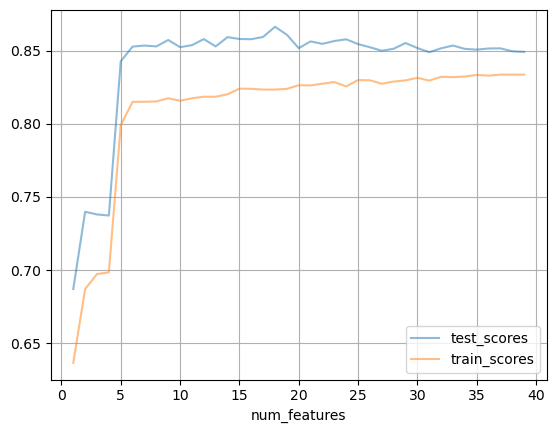

In [16]:
# Create a DataFrame to hold training and testing R2 scores
df = pd.DataFrame(data={'test_scores':test_scores, 'train_scores':train_scores})

# reset index to create a feature count axis
df.reset_index(inplace=True)
df.rename(columns={'index':'num_features'}, inplace=True)

# Adjust zero-based index to 1-based feature count
df.num_features = df.num_features + 1

# Plot performance curves comparing train and test R2 scores across feature counts
df.plot(x='num_features', y=['test_scores','train_scores'], grid =True, alpha=0.5)

# Conclusion

Based on the feature selection plot:
- A sharp increase in performance occurs at **5 features**, where the testing $R^2$ score jumps from ~0.74 to over **0.84**, and the training score reaches **0.80**.
- Beyond 5 features, both scores plateau with only marginal variations, indicating diminishing returns and unnecessary model complexity.
- Therefore, a model with **5 features** provides the optimal balance of predictive accuracy, simplicity, and generalizability for predicting automobile MPG.